In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from pathlib import Path

print("TensorFlow:", tf.__version__)

# Download FER2013
dataset_path = kagglehub.dataset_download("msambare/fer2013")

print("Dataset downloaded to:", dataset_path)
print("\nDataset folders and files:")

for item in Path(dataset_path).iterdir():
    print(item.name)

C:\Users\USER\anaconda3\envs\dl-ex01\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow: 2.15.1


100%|██████████| 60.3M/60.3M [00:04<00:00, 14.2MB/s]

Extracting files...


Dataset downloaded to: C:\Users\USER\.cache\kagglehub\datasets\msambare\fer2013\versions\1

Dataset folders and files:
test
train


Expression Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

Dataset Distribution:
angry: Train=3995, Test=958
disgust: Train=436, Test=111
fear: Train=4097, Test=1024
happy: Train=7215, Test=1774
neutral: Train=4965, Test=1233
sad: Train=4830, Test=1247
surprise: Train=3171, Test=831


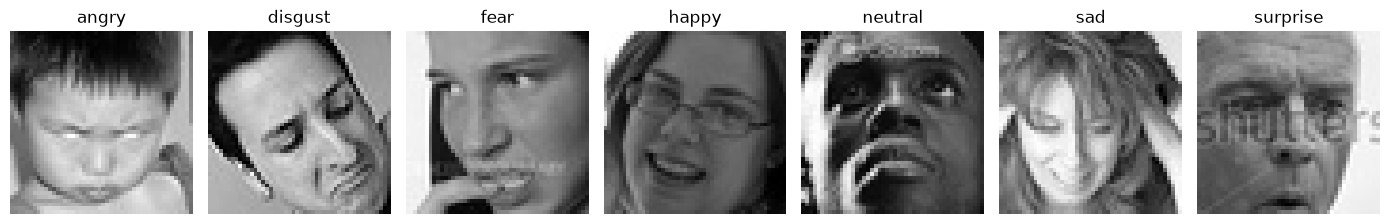

In [3]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Dataset folders
data_dir = Path(dataset_path)

train_dir = data_dir / "train"
test_dir = data_dir / "test"

# List the expression categories
class_names = sorted(
    [folder.name for folder in train_dir.iterdir()
     if folder.is_dir()]
)

print("Expression Classes:", class_names)

# Count images in each class
print("\nDataset Distribution:")

for class_name in class_names:
    train_count = len(list((train_dir / class_name).glob("*.jpg")))
    test_count = len(list((test_dir / class_name).glob("*.jpg")))

    print(f"{class_name}: Train={train_count}, Test={test_count}")

# Display one example image per class
plt.figure(figsize=(14, 3))

for i, class_name in enumerate(class_names):
    image_path = next((train_dir / class_name).glob("*.jpg"))
    img = Image.open(image_path)

    plt.subplot(1, len(class_names), i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
from tensorflow.keras import layers, models

IMG_SIZE = (48, 48)
BATCH_SIZE = 64
SEED = 42

# Training dataset
train_full = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    label_mode="int"
)

# Validation dataset
val_full = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    label_mode="int"
)

# Unseen testing dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_full.class_names
assert class_names == test_ds.class_names

# Limit training workload for our initial experiments
train_ds = train_full.take(160).cache().prefetch(tf.data.AUTOTUNE)
val_ds = val_full.take(40).cache().prefetch(tf.data.AUTOTUNE)

print("\nClasses:", class_names)
print("Number of classes:", len(class_names))

for images, labels in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Pixel range:", float(tf.reduce_min(images)),
          "to", float(tf.reduce_max(images)))

Found 28709 files belonging to 7 classes.
Using 22968 files for training.
Found 28709 files belonging to 7 classes.
Using 5741 files for validation.
Found 7178 files belonging to 7 classes.

Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Number of classes: 7
Image shape: (64, 48, 48, 1)
Pixel range: 0.0 to 255.0


In [7]:
# Baseline Dense Neural Network
tf.keras.utils.set_random_seed(42)

baseline_model = models.Sequential([
    layers.Input(shape=(48, 48, 1)),
    layers.Rescaling(1./255),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(7, activation="softmax")
])

baseline_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()

history_baseline = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    verbose=1
)

# Save baseline model
baseline_model.save("baseline_dense.keras")

print("\nBaseline model saved!")
print("Final training accuracy:",
      round(history_baseline.history["accuracy"][-1], 4))
print("Final validation accuracy:",
      round(history_baseline.history["val_accuracy"][-1], 4))



Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling (Rescaling)       (None, 48, 48, 1)         0         
                                                                 
 flatten (Flatten)           (None, 2304)              0         
                                                                 
 dense (Dense)               (None, 128)               295040    
                                                                 
 dropout (Dropout)           (None, 128)               0         
                                                                 
 dense_1 (Dense)             (None, 7)                 903       
                                                                 
Total params: 295943 (1.13 MB)
Trainable params: 295943 (1.13 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Epoch 1/5


160/16

Rescaling(1./255) converts pixel values from 0–255 to 0–1.



Flatten() converts the 48×48 image into 2,304 input values.



Dense(128) learns patterns from those values.



Dropout(0.3) helps reduce overfitting.



Dense(7, softmax) produces probabilities for our seven expression categories.

In [10]:
from tensorflow.keras import layers, models, callbacks

tf.keras.utils.set_random_seed(42)

# Step 1: Define the improved CNN
cnn_model = models.Sequential([
    layers.Input(shape=(48, 48, 1)),
    layers.Rescaling(1./255),

    # Data augmentation
    layers.RandomFlip("horizontal"),

    # Convolution Block 1
    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.35),
    layers.Dense(7, activation="softmax")
])

# Step 2: Compile
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Stop automatically if validation performance stops improving
early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Step 3: Train
history_cnn = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=[early_stop],
    verbose=1
)

# Save the trained model
cnn_model.save("fer2013_cnn.keras")

# Evaluate after restoring the best weights
val_loss, val_accuracy = cnn_model.evaluate(val_ds, verbose=0)

print("\nCNN training completed!")
print("Epochs completed:", len(history_cnn.history["loss"]))
print("Best CNN Validation Accuracy:", round(val_accuracy * 100, 2), "%")
print("Baseline Validation Accuracy: 29.45%")
print("Model saved as fer2013_cnn.keras")


Epoch 1/12
160/160 [==============================] - 7s 36ms/step - loss: 1.8222 - accuracy: 0.2442 - val_loss: 1.7684 - val_accuracy: 0.2715
Epoch 2/12
160/160 [==============================] - 6s 35ms/step - loss: 1.7305 - accuracy: 0.2993 - val_loss: 1.6557 - val_accuracy: 0.3500
Epoch 3/12
160/160 [==============================] - 6s 34ms/step - loss: 1.6444 - accuracy: 0.3562 - val_loss: 1.5806 - val_accuracy: 0.3762
Epoch 4/12
160/160 [==============================] - 5s 34ms/step - loss: 1.5786 - accuracy: 0.3935 - val_loss: 1.5190 - val_accuracy: 0.4207
Epoch 5/12
160/160 [==============================] - 6s 36ms/step - loss: 1.5330 - accuracy: 0.4131 - val_loss: 1.4970 - val_accuracy: 0.4215
Epoch 6/12
160/160 [==============================] - 6s 37ms/step - loss: 1.4887 - accuracy: 0.4243 - val_loss: 1.4631 - val_accuracy: 0.4355
Epoch 7/12
160/160 [==============================] - 6s 38ms/step - loss: 1.4509 - accuracy: 0.4419 - val_loss: 1.4252 - val_accuracy: 0.452

113/113 [==============================] - 26s 228ms/step

CNN TEST ACCURACY:
48.61%

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

       angry       0.36      0.35      0.35       958
     disgust       0.00      0.00      0.00       111
        fear       0.32      0.16      0.22      1024
       happy       0.60      0.81      0.69      1774
     neutral       0.42      0.53      0.47      1233
         sad       0.40      0.33      0.36      1247
    surprise       0.66      0.60      0.63       831

    accuracy                           0.49      7178
   macro avg       0.39      0.40      0.39      7178
weighted avg       0.46      0.49      0.46      7178



<Figure size 900x700 with 0 Axes>

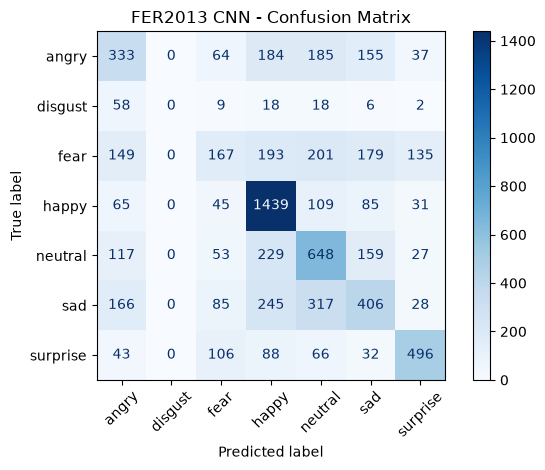

In [12]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Get predictions on unseen test images
y_prob = cnn_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Get actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Calculate test accuracy
test_accuracy = accuracy_score(y_true, y_pred)

print("\nCNN TEST ACCURACY:")
print(f"{test_accuracy * 100:.2f}%")

# Classification report
print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("FER2013 CNN - Confusion Matrix")
plt.tight_layout()
plt.show()

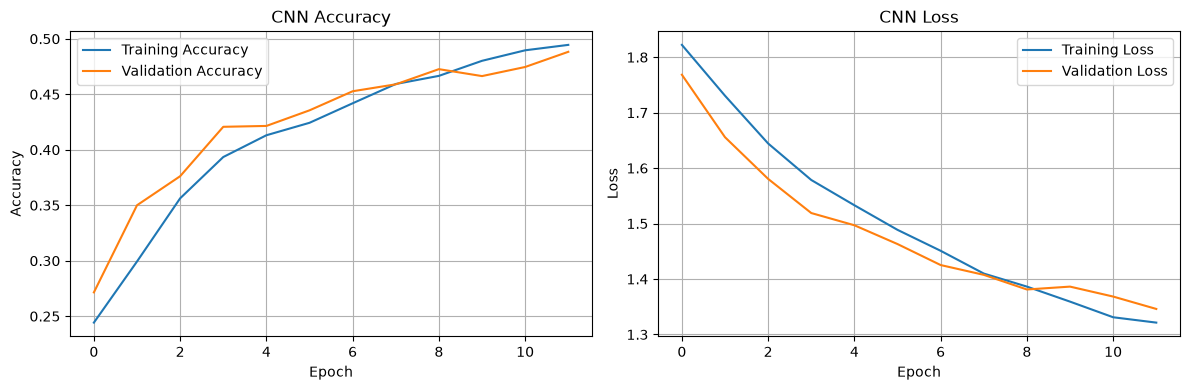

In [14]:
# Compare baseline and CNN learning curves

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Accuracy
axes[0].plot(
    history_cnn.history["accuracy"],
    label="Training Accuracy"
)
axes[0].plot(
    history_cnn.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(
    history_cnn.history["loss"],
    label="Training Loss"
)
axes[1].plot(
    history_cnn.history["val_loss"],
    label="Validation Loss"
)
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [16]:
%%writefile app.py
from pathlib import Path
import cv2
import gradio as gr
import numpy as np
import tensorflow as tf

MODEL_PATH = Path(__file__).resolve().parent / "fer2013_cnn.keras"

CLASSES = [
    "angry", "disgust", "fear", "happy",
    "neutral", "sad", "surprise"
]

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

face_detector = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

def predict_expression(image):
    if image is None:
        return None, None, "Upload an image or capture a webcam photo."

    # Gradio supplies an RGB image
    image = np.asarray(image, dtype=np.uint8)
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # Detect faces
    faces = face_detector.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    if len(faces) > 0:
        # Select the largest detected face
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

        # Add a little padding
        pad = int(0.1 * max(w, h))

        x1 = max(0, x - pad)
        y1 = max(0, y - pad)
        x2 = min(gray.shape[1], x + w + pad)
        y2 = min(gray.shape[0], y + h + pad)

        face = gray[y1:y2, x1:x2]
        status = "Face detected successfully."
    else:
        face = gray
        status = "No face detected. Using the complete image."

    # Match FER2013 training input: 48x48 grayscale
    face = cv2.resize(face, (48, 48))
    model_input = face.astype("float32").reshape(1, 48, 48, 1)

    # Our model already contains a Rescaling layer
    probabilities = model.predict(model_input, verbose=0)[0]

    result = {
        name.capitalize(): float(prob)
        for name, prob in zip(CLASSES, probabilities)
    }

    best_index = int(np.argmax(probabilities))
    predicted_class = CLASSES[best_index].capitalize()

    message = (
        f"Predicted expression: {predicted_class}\n"
        f"Model score: {probabilities[best_index] * 100:.1f}%\n"
        f"{status}\n"
        "These scores describe facial-expression classes, "
        "not a person's actual emotional state."
    )

    return result, face, message


demo = gr.Interface(
    fn=predict_expression,
    inputs=gr.Image(
        sources=["upload", "webcam"],
        type="numpy",
        image_mode="RGB",
        label="Upload Photo or Capture from Webcam"
    ),
    outputs=[
        gr.Label(
            num_top_classes=7,
            label="Expression Probabilities"
        ),
        gr.Image(
            label="Processed Face (48x48)",
            interactive=False
        ),
        gr.Textbox(label="Prediction Details", lines=4)
    ],
    title="FaceSense | Facial Expression Recognition",
    description=(
        "An interactive FER2013 CNN project built using "
        "TensorFlow, Keras, OpenCV and Gradio. "
        "Upload a face image or take a webcam snapshot."
    ),
    theme=gr.themes.Soft()
)

if __name__ == "__main__":
    demo.launch()

Writing app.py


In [18]:
from app import demo

demo.launch(
    share=False,
    inline=False
)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [20]:
# Close the local Gradio server
demo.close()

# Relaunch with a public share link
demo.launch(
    share=True,
    inline=False
)

Closing server running on port: 7860
* Running on local URL:  http://127.0.0.1:7860

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


2026/10/26 14:12:20 [W] [service.go:132] login to server failed: dial tcp 44.237.78.176:7000: i/o timeout


In [22]:
%%writefile streamlit_app.py
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import streamlit as st
import tensorflow as tf
from PIL import Image

st.set_page_config(
    page_title="FaceSense",
    page_icon="🎭",
    layout="wide"
)

CLASSES = [
    "angry", "disgust", "fear", "happy",
    "neutral", "sad", "surprise"
]

@st.cache_resource
def load_resources():
    model_path = Path(__file__).resolve().parent / "fer2013_cnn.keras"
    model = tf.keras.models.load_model(model_path, compile=False)
    detector = cv2.CascadeClassifier(
        cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
    )
    return model, detector

model, detector = load_resources()

st.title("🎭 FaceSense")
st.subheader("Facial Expression Recognition with Deep Learning")
st.write("Upload a face image or capture one using your webcam.")

st.sidebar.header("About FaceSense")
st.sidebar.write("Dataset: FER2013")
st.sidebar.write("Model: Convolutional Neural Network")
st.sidebar.metric("Test Accuracy", "48.61%")
st.sidebar.write("Classes: 7 facial expressions")

mode = st.radio(
    "Select input method",
    ["Upload Image", "Use Webcam"],
    horizontal=True
)

if mode == "Upload Image":
    uploaded = st.file_uploader(
        "Choose a face image",
        type=["jpg", "jpeg", "png"]
    )
else:
    uploaded = st.camera_input("Capture your face")

if uploaded is not None:
    image = Image.open(uploaded).convert("RGB")
    rgb = np.array(image)

    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    faces = detector.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=5,
        minSize=(30, 30)
    )

    detected = len(faces) > 0

    if detected:
        x, y, w, h = max(
            faces, key=lambda f: f[2] * f[3]
        )
        pad = int(0.1 * max(w, h))
        face = gray[
            max(0, y-pad):min(gray.shape[0], y+h+pad),
            max(0, x-pad):min(gray.shape[1], x+w+pad)
        ]
    else:
        face = gray

    face = cv2.resize(face, (48, 48))
    input_data = face.astype("float32").reshape(1, 48, 48, 1)

    probabilities = model.predict(input_data, verbose=0)[0]
    best = int(np.argmax(probabilities))

    left, right = st.columns(2)

    with left:
        st.image(image, caption="Original Image", use_container_width=True)
        st.image(face, caption="Processed Face (48×48)", width=150)

    with right:
        st.success(f"Predicted Expression: {CLASSES[best].capitalize()}")
        st.metric("Model Score", f"{probabilities[best]*100:.1f}%")

        results = pd.DataFrame({
            "Expression": [c.capitalize() for c in CLASSES],
            "Probability": probabilities
        }).set_index("Expression")

        st.bar_chart(results)

    if not detected:
        st.warning("No face detected. Prediction used the entire image.")

    st.caption(
        "This model classifies visible facial expressions, "
        "not a person's actual emotional state. "
        "Prediction scores are not guaranteed to be calibrated probabilities."
    )

Writing streamlit_app.py


In [28]:
%%writefile requirements.txt
streamlit==1.40.2
tensorflow-cpu==2.15.1
numpy==1.26.4
pandas>=2.0,<3
Pillow>=10,<12
protobuf==4.25.3
pyarrow==15.0.2
opencv-python-headless==4.11.0.86

Overwriting requirements.txt


In [30]:
from pathlib import Path

files = [
    "streamlit_app.py",
    "fer2013_cnn.keras",
    "requirements.txt",
    "Image_Neural_Network_FER2013.ipynb"
]

for filename in files:
    p = Path(filename)
    if p.exists():
        print(f"READY: {filename} ({p.stat().st_size / 1024**2:.2f} MB)")
    else:
        print(f"MISSING: {filename}")

READY: streamlit_app.py (0.00 MB)
READY: fer2013_cnn.keras (2.01 MB)
READY: requirements.txt (0.00 MB)
READY: Image_Neural_Network_FER2013.ipynb (0.21 MB)
